In [1]:
!unzip -o "/content/archive (2).zip" -d "/content/fraud_data"

Archive:  /content/archive (2).zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/archive (2).zip or
        /content/archive (2).zip.zip, and cannot find /content/archive (2).zip.ZIP, period.


In [3]:
import os

os.listdir("/content")

['.config', 'archive (2).zip', '.ipynb_checkpoints', 'sample_data']

In [4]:
import zipfile
import os

zip_path = "/content/archive (2).zip"
extract_path = "/content/fraud_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['creditcard.csv']


In [5]:
import os

for root, dirs, files in os.walk("/content/fraud_data"):
    for file in files:
        print(file)

creditcard.csv


In [6]:
import pandas as pd

df = pd.read_csv("/content/fraud_data/creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nFraud and Normal Transactions:")
print(df['Class'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

In [8]:
fraud_count = df['Class'].value_counts()

fraud_percentage = (df['Class'].sum() / len(df)) * 100

print("Normal Transactions:", fraud_count[0])
print("Fraud Transactions:", fraud_count[1])
print("Fraud Percentage:", round(fraud_percentage, 3), "%")

Normal Transactions: 284315
Fraud Transactions: 492
Fraud Percentage: 0.173 %


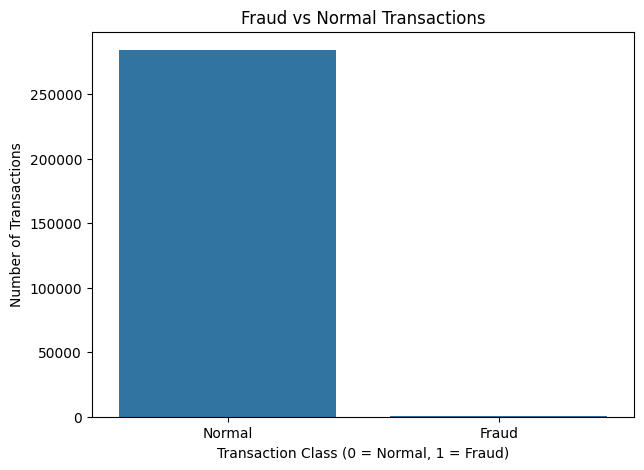

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

sns.countplot(x='Class', data=df)

plt.title("Fraud vs Normal Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ['Normal', 'Fraud'])
plt.show()

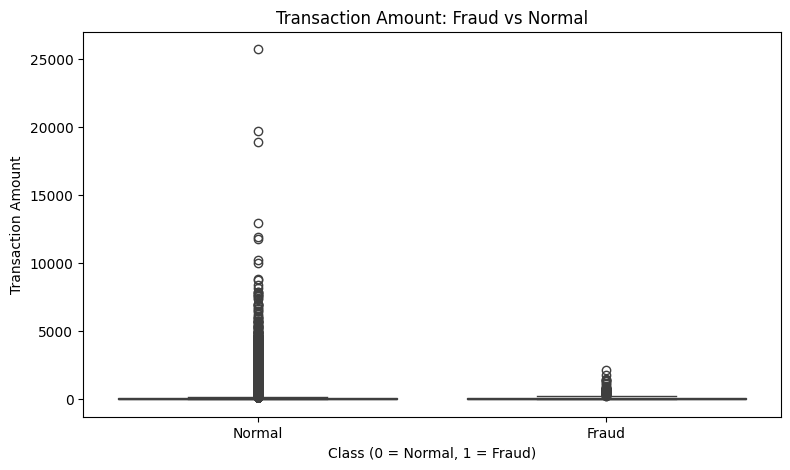

In [10]:
plt.figure(figsize=(9,5))

sns.boxplot(x='Class', y='Amount', data=df)

plt.title("Transaction Amount: Fraud vs Normal")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.xticks([0, 1], ['Normal', 'Fraud'])
plt.show()

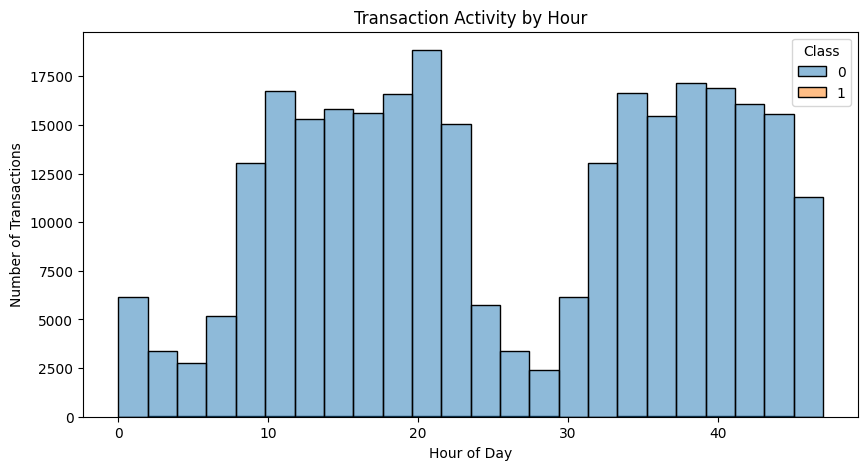

In [11]:
df['Hour'] = (df['Time'] // 3600).astype(int)

plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='Hour',
    hue='Class',
    bins=24,
    multiple='layer'
)

plt.title("Transaction Activity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())

Training data: (227845, 31)
Testing data: (56962, 31)

Training fraud cases: 394
Testing fraud cases: 98


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model1 = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

model1.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [15]:
from sklearn.ensemble import RandomForestClassifier

model2 = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model2.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [16]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

models = {
    "Logistic Regression": model1,
    "Random Forest": model2
}

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n", "=" * 40)
    print(name)
    print("=" * 40)

    print(classification_report(y_test, predictions))
    print("AUC-ROC:", roc_auc_score(y_test, probabilities))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

AUC-ROC: 0.9721761840639462
Confusion Matrix:
[[55470  1394]
 [    8    90]]

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

AUC-ROC: 0.9478299637947469
Confusion Matrix:
[[56861     3]
 [   25    73]]


                 Model  Precision    Recall  F1-Score
0  Logistic Regression   0.060647  0.918367   0.11378
1        Random Forest   0.960526  0.744898   0.83908


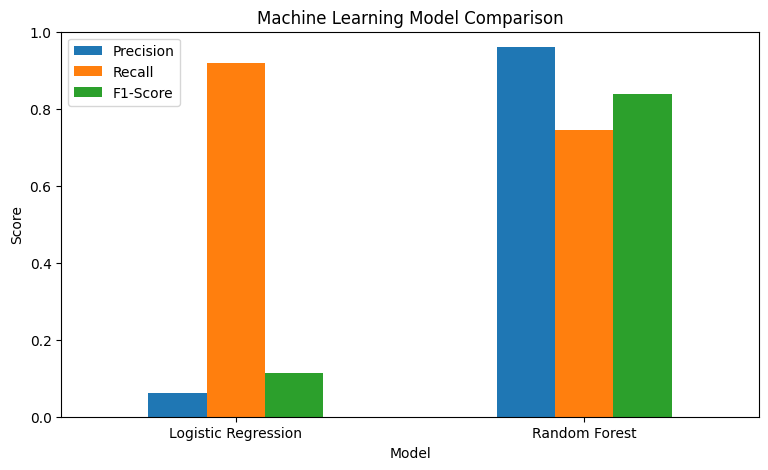

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

results = []

for name, model in models.items():
    pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

print(results_df)

results_df.set_index('Model').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

Top 10 Important Features:
V14    0.189149
V10    0.145279
V12    0.096592
V4     0.094126
V11    0.076028
V17    0.067754
V3     0.051165
V7     0.031946
V16    0.027804
V2     0.024598
dtype: float64


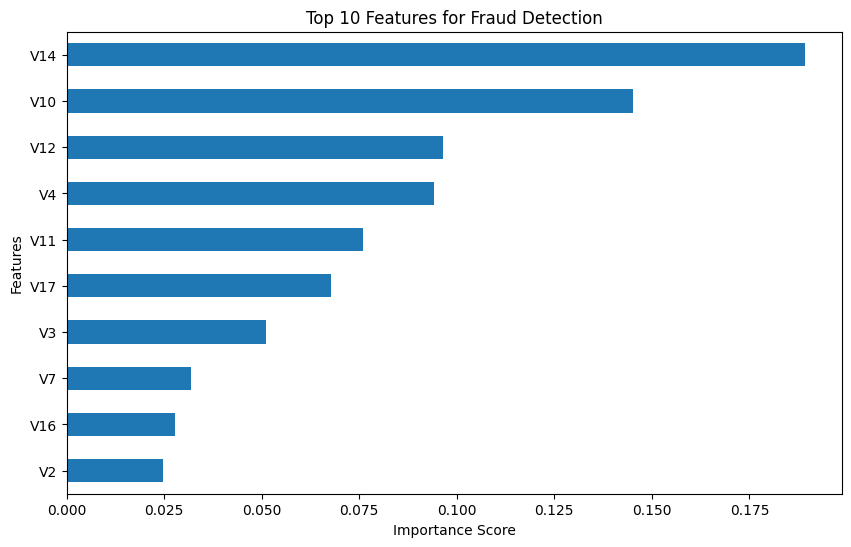

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model2.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
print(importance.head(10))

plt.figure(figsize=(10, 6))
importance.head(10).sort_values().plot(kind='barh')

plt.title("Top 10 Features for Fraud Detection")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

## Project Observations and Analysis

### 1. Class Imbalance
The dataset contains many more normal transactions than fraudulent transactions. Therefore, accuracy alone is not a reliable measure of fraud detection performance.

### 2. Precision and Recall
- **Precision:** Measures how many transactions predicted as fraud are actually fraudulent.
- **Recall:** Measures how many actual fraudulent transactions are correctly detected.

Recall is especially important in fraud detection because missing a fraudulent transaction can cause financial loss. However, precision is also important to reduce unnecessary alerts.

### 3. Model Comparison
Logistic Regression and Random Forest were trained using class balancing. Their Precision, Recall, F1-score and AUC-ROC results were compared to understand their performance.

### 4. Feature Importance
Random Forest feature importance helps identify which transaction characteristics contribute most to fraud prediction.

### 5. Scalability
For processing one million transactions per hour, the system could use distributed processing, real-time streaming, optimized machine learning models and cloud infrastructure.

## Conclusion

This project demonstrates how machine learning can help identify fraudulent financial transactions. Two classification models were developed and evaluated using suitable performance metrics. The analysis shows the importance of handling imbalanced datasets and selecting appropriate evaluation measures for fraud detection.